<a href="https://colab.research.google.com/github/arikelasumanjali-coder/DL/blob/main/skill8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available")

PyTorch Version: 2.14.1+cu130
CUDA Available: True
GPU Name: Tesla T4


In [ ]:
import torch
import torchvision
import time
import numpy as np

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected Device:", device)

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Selected Device: cuda


In [ ]:
import torchvision.models as models

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

model = model.to(device)
model.eval()

print("Model loaded successfully!")
print("Model device:", next(model.parameters()).device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s]


Model loaded successfully!
Model device: cuda:0


In [ ]:
import torch

# Create a sample image
input_data = torch.randn(1, 3, 224, 224)

# Move input data to GPU
input_data = input_data.to(device)

print("Input Shape:", input_data.shape)
print("Input Device:", input_data.device)

Input Shape: torch.Size([1, 3, 224, 224])
Input Device: cuda:0


In [ ]:
with torch.no_grad():
    start_time = time.time()

    output = model(input_data)

    torch.cuda.synchronize()
    end_time = time.time()

print("Inference completed!")
print("Output Shape:", output.shape)
print("Inference Time:", (end_time - start_time) * 1000, "ms")

Inference completed!
Output Shape: torch.Size([1, 1000])
Inference Time: 1429.7997951507568 ms


In [ ]:
import time
import torch
import torchvision.models as models

# Create separate CPU and GPU models
cpu_model = models.resnet18(weights=None)
cpu_model.load_state_dict(model.state_dict())
cpu_model = cpu_model.to("cpu")
cpu_model.eval()

gpu_model = models.resnet18(weights=None)
gpu_model.load_state_dict(model.state_dict())
gpu_model = gpu_model.to("cuda")
gpu_model.eval()

# Prepare input
cpu_input = torch.randn(1, 3, 224, 224).to("cpu")
gpu_input = cpu_input.to("cuda")

# Warm-up GPU
with torch.no_grad():
    for _ in range(5):
        gpu_model(gpu_input)

torch.cuda.synchronize()

# CPU inference
start = time.time()

with torch.no_grad():
    for _ in range(20):
        cpu_output = cpu_model(cpu_input)

cpu_time = (time.time() - start) / 20 * 1000

# GPU inference
torch.cuda.synchronize()
start = time.time()

with torch.no_grad():
    for _ in range(20):
        gpu_output = gpu_model(gpu_input)

torch.cuda.synchronize()
gpu_time = (time.time() - start) / 20 * 1000

print("Average CPU Inference:", round(cpu_time, 2), "ms")
print("Average GPU Inference:", round(gpu_time, 2), "ms")

Average CPU Inference: 77.11 ms
Average GPU Inference: 3.89 ms


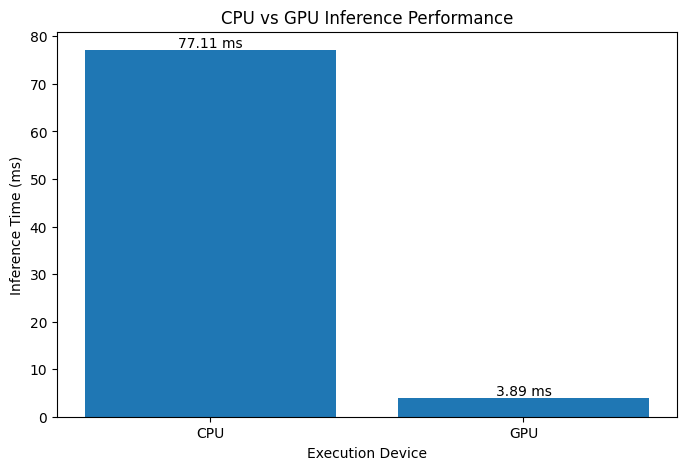

In [ ]:
import matplotlib.pyplot as plt

devices = ["CPU", "GPU"]
times = [cpu_time, gpu_time]

plt.figure(figsize=(8, 5))
bars = plt.bar(devices, times)

plt.title("CPU vs GPU Inference Performance")
plt.xlabel("Execution Device")
plt.ylabel("Inference Time (ms)")

for bar, value in zip(bars, times):
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height(),
             f"{value:.2f} ms",
             ha="center", va="bottom")

plt.show()

In [ ]:
import torch
import time

batch_sizes = [1, 2, 4, 8, 16]
inference_times = []
throughputs = []

for batch in batch_sizes:

    input_data = torch.randn(batch, 3, 224, 224).cuda()

    # Warm-up
    with torch.no_grad():
        gpu_model(input_data)

    torch.cuda.synchronize()
    start = time.time()

    with torch.no_grad():
        for _ in range(20):
            output = gpu_model(input_data)

    torch.cuda.synchronize()

    avg_time = (time.time() - start) / 20 * 1000

    inference_times.append(avg_time)
    throughputs.append(batch / (avg_time / 1000))

    print("Batch Size:", batch)
    print("Inference Time:", round(avg_time, 2), "ms")
    print("Throughput:", round(throughputs[-1], 2), "images/sec")

Batch Size: 1
Inference Time: 3.86 ms
Throughput: 258.94 images/sec
Batch Size: 2
Inference Time: 5.38 ms
Throughput: 371.48 images/sec
Batch Size: 4
Inference Time: 6.04 ms
Throughput: 662.42 images/sec
Batch Size: 8
Inference Time: 9.31 ms
Throughput: 859.45 images/sec
Batch Size: 16
Inference Time: 14.28 ms
Throughput: 1120.26 images/sec


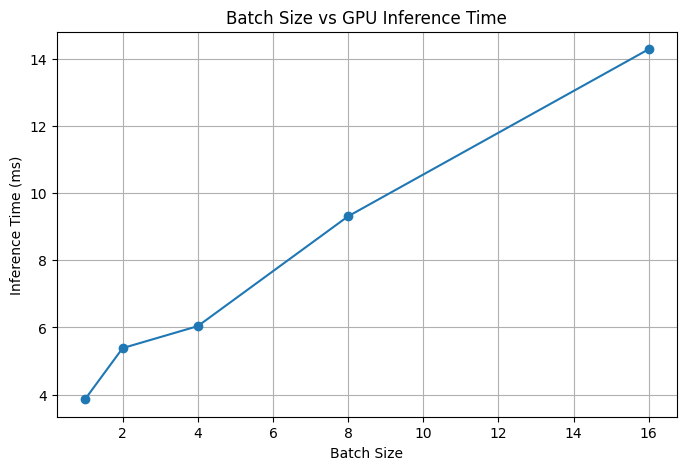

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(batch_sizes, inference_times, marker='o')

plt.title("Batch Size vs GPU Inference Time")
plt.xlabel("Batch Size")
plt.ylabel("Inference Time (ms)")
plt.grid(True)
plt.show()

In [ ]:
print("GPU Memory Allocated:",
      round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

print("GPU Memory Reserved:",
      round(torch.cuda.memory_reserved() / 1024**2, 2), "MB")

print("Total GPU Memory:",
      round(torch.cuda.get_device_properties(0).total_memory / 1024**2, 2), "MB")

GPU Memory Allocated: 107.96 MB
GPU Memory Reserved: 300.0 MB
Total GPU Memory: 14912.69 MB


In [ ]:
print("========== SYSTEM PERFORMANCE ANALYSIS ==========")

print("CPU Inference Time:", round(cpu_time, 2), "ms")
print("GPU Inference Time:", round(gpu_time, 2), "ms")

print("\nGPU Memory Allocated:",
      round(torch.cuda.memory_allocated() / 1024**2, 2), "MB")

print("GPU Memory Reserved:",
      round(torch.cuda.memory_reserved() / 1024**2, 2), "MB")

print("\nGPU Throughput:")
for batch, throughput in zip(batch_sizes, throughputs):
    print(batch, "images:", round(throughput, 2), "images/sec")

print("\n========== BOTTLENECK ANALYSIS ==========")

if gpu_time < cpu_time:
    print("GPU provides faster inference than CPU.")
else:
    print("GPU does not provide faster inference for this workload.")

if throughputs[-1] > throughputs[0]:
    print("Larger batches improve GPU throughput.")
else:
    print("Larger batches do not improve GPU throughput.")

print("GPU memory usage was measured successfully.")

========== SYSTEM PERFORMANCE ANALYSIS ==========
CPU Inference Time: 77.11 ms
GPU Inference Time: 3.89 ms

GPU Memory Allocated: 107.96 MB
GPU Memory Reserved: 300.0 MB

GPU Throughput:
1 images: 258.94 images/sec
2 images: 371.48 images/sec
4 images: 662.42 images/sec
8 images: 859.45 images/sec
16 images: 1120.26 images/sec

========== BOTTLENECK ANALYSIS ==========
GPU provides faster inference than CPU.
Larger batches improve GPU throughput.
GPU memory usage was measured successfully.


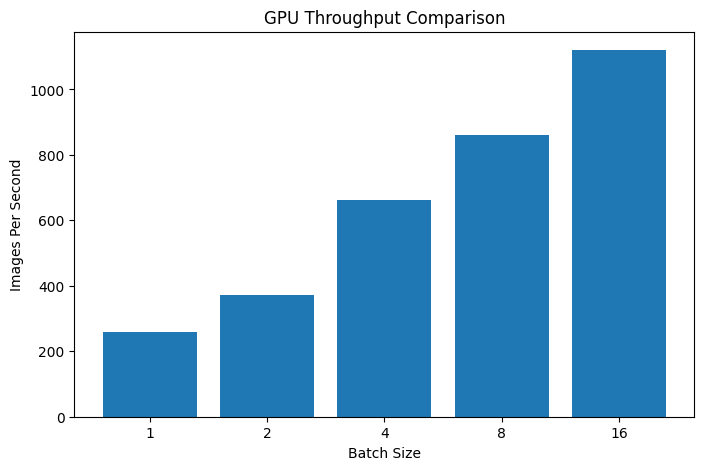

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    [str(x) for x in batch_sizes],
    throughputs
)

plt.title("GPU Throughput Comparison")
plt.xlabel("Batch Size")
plt.ylabel("Images Per Second")

plt.show()